# Episode 10: Gradient Descent, Part 2
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2010%20-%20Gradient%20Descent%2C%20Part%202/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*. Gradient Descent, part 2: mean versus sum, and mini-batches.

The episode works every calculation by hand, and stops to let you try things before it shows the answer. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. Where the video pauses, the notebook says **Predict first**: make your guess, then run the cell. It uses only `numpy` and `matplotlib` (both already in Colab), plus Python's built-in `fractions` so the thirds and fifteenths print exactly: choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | The experiment: line A, η = 0.1, one step on the mean, then three steps on the sum | 1/3 → 0.133 · 1.2, 5.95, 31.7 |
| 2 | One dot at a time: the per-dot gradients, the mean and the sum, and both steps by hand | (0, 0), (0, 0), (6, 2) · (2, 2/3) · (6, 2) · 1.8, −1/15 · 1.4, −0.2 · 3.6 ÷ 3 = 1.2 |
| 3 | Why: the steepness of the mean loss, the safe limits, a sweep of η, and the rule "η on the sum = N × η on the mean" | ≈ 0.18 · ≈ 0.06 · 0.1 → 0.3 |
| 4 | Check 1: the sum of four copies of 3z² | 12z² · 1/12 ≈ 0.083 · 2.4 · −1.4 |
| 5 | Mini-batches: draws from the W slopes 0, 0, 6; the variance for one, two and eight per batch; the typical miss | 2 · 8, 4, 1 · ≈ 2.8, 2, 1 · 100× → 10× |
| 6 | Line B: slopes that add up to zero, and a step that still moves at the bottom | 1/3, −4/3, 1 |
| 7 | Check 2: slopes 0, 3, 9 | 4 · 14 · 7 · ≈ 3.7 → ≈ 2.6 |
| 8 | Try it yourself, with self-checks | your numbers |

The three dots and both losses are exact, so Parts 1 to 4, 6 and 7 are exact arithmetic (up to floating-point rounding). In Part 5 the variances come from listing every possible mini-batch, so they are exact too; only the simulated draws are random, and they use a fixed seed. **Error** always means the dot's height minus the line's height, y − ŷ. The step size, also called the learning rate, is **η** (eta); the steepness is **κ** (kappa), as in Episode 9.

## Setup

In [1]:
from fractions import Fraction as F

import matplotlib.pyplot as plt
import numpy as np

STEEL, GOLD, CORAL, MUTED = "#8FB4E8", "#FFC400", "#FF4D3D", "#8B98AE"   # the video's colours
DOT = "#1B2A4A"                                                          # the dots (white on the video's navy)

u = np.array([1.0, 2.0, 3.0])          # Episode 7's three dots: inputs ...
y = np.array([2.0, 4.0, 5.0])          # ... and heights
N = len(u)
LINE_A = (2.0, 0.0)                    # W = 2, beta = 0
LINE_B = (1.5, 2 / 3)                  # the best line (Episode 7)


def fmt(x):
    """Print a number the way you would write it on paper: 0.64, not 0.6400000000000001."""
    return f"{round(float(x), 8):.10g}"


def errors(W, b):
    """Error = the dot's height minus the line's height, for each dot."""
    return y - (W * u + b)


def mse(W, b):
    """The score used all episode: the average of the squared errors."""
    return float((errors(W, b) ** 2).mean())


def dot_gradients(W, b):
    """One row per dot: (slope for W, slope for beta) = (-2 x input x error, -2 x error)."""
    e = errors(W, b)
    return np.column_stack([-2 * u * e, -2 * e])


def walk(reduce, eta, steps, start=LINE_A, cap=1e6):
    """Gradient descent on the three dots. reduce is "mean" or "sum": how the per-dot gradients are combined.
    Returns the (W, beta) points and the MSE score at each one. Stops early once the score passes cap."""
    p = np.array(start, dtype=float)
    pts, scores = [p], [mse(*p)]
    for _ in range(steps):
        g = dot_gradients(*p)
        g = g.mean(axis=0) if reduce == "mean" else g.sum(axis=0)
        p = p - eta * g
        pts.append(p)
        scores.append(mse(*p))
        if scores[-1] > cap:
            break
    return np.array(pts), scores


def batch_stats(slopes, m):
    """List EVERY mini-batch of m picks (each pick put back, so len(slopes)^m batches, all equally likely).
    Returns the batch averages, their mean, and their variance, as exact fractions."""
    slopes = [F(s) for s in slopes]
    picks = np.indices((len(slopes),) * m).reshape(m, -1).T          # every way to pick m times
    averages = [sum(slopes[i] for i in row) / m for row in picks]
    mean = sum(averages) / len(averages)
    variance = sum((a - mean) ** 2 for a in averages) / len(averages)
    return averages, mean, variance

## Part 1 · The experiment

### Step 1: one calm step
Episode 7's three dots are (1, 2), (2, 4), (3, 5). Line A is ŷ = 2u + 0. Its errors are 0, 0, −1, so its loss, the **mean** of the squared errors, is 1/3. Take one step of gradient descent with η = 0.1.

In [2]:
assert np.allclose(errors(*LINE_A), [0, 0, -1])
assert np.isclose(mse(*LINE_A), 1 / 3)
pts_mean, scores_mean = walk("mean", 0.1, 3)
print(f"line A: errors {[fmt(e) for e in errors(*LINE_A)]}, loss {mse(*LINE_A):.3f}")
print(f"one step on the MEAN, eta = 0.1: loss {scores_mean[0]:.3f} -> {scores_mean[1]:.3f}")
assert np.isclose(scores_mean[1], 2 / 15) and round(scores_mean[1], 3) == 0.133
assert all(b < a for a, b in zip(scores_mean, scores_mean[1:]))        # it keeps falling
print("A nice, calm step.")

line A: errors ['0', '0', '-1'], loss 0.333
one step on the MEAN, eta = 0.1: loss 0.333 -> 0.133
A nice, calm step.


### Step 2: change one word
Now write the loss as the **sum** of the three squared errors instead of their mean. Same dots, same line, same η = 0.1.

**Predict first.** Does the line get better, stay about the same, or get worse?

To compare fairly, the score is kept the same way as before: the mean squared error of the new line.

In [3]:
pts_sum, scores_sum = walk("sum", 0.1, 3)
print("steps on the SUM, eta = 0.1 (score kept as the mean squared error):")
print("  " + "  ->  ".join(f"{s:.4g}" for s in scores_sum))
assert np.isclose(scores_sum[1], 1.2)
assert round(scores_sum[2], 3) == 5.947 and round(scores_sum[2], 2) == 5.95
assert round(scores_sum[3], 2) == 31.71 and round(scores_sum[3], 1) == 31.7
assert all(b > a for a, b in zip(scores_sum, scores_sum[1:]))          # worse every step
print("One word turned a calm walk into an explosion.")

steps on the SUM, eta = 0.1 (score kept as the mean squared error):
  0.3333  ->  1.2  ->  5.947  ->  31.71
One word turned a calm walk into an explosion.


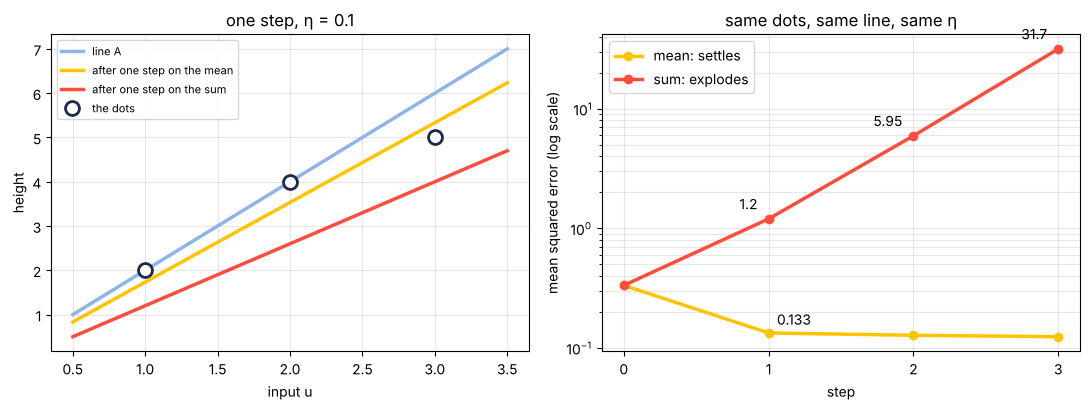

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
uu = np.array([0.5, 3.5])
ax.plot(uu, LINE_A[0] * uu + LINE_A[1], color=STEEL, lw=2.5, label="line A")
ax.plot(uu, pts_mean[1][0] * uu + pts_mean[1][1], color=GOLD, lw=2.5, label="after one step on the mean")
ax.plot(uu, pts_sum[1][0] * uu + pts_sum[1][1], color=CORAL, lw=2.5, label="after one step on the sum")
ax.plot(u, y, "o", color="white", mec=DOT, mew=2, ms=10, label="the dots", zorder=5)
ax.set_xlabel("input u"); ax.set_ylabel("height"); ax.set_title("one step, η = 0.1"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1]
ax.semilogy(range(4), scores_mean, "-o", color=GOLD, lw=2.5, label="mean: settles")
ax.semilogy(range(4), scores_sum, "-o", color=CORAL, lw=2.5, label="sum: explodes")
for k in (1, 2, 3):
    ax.annotate(f"{scores_sum[k]:.3g}", (k, scores_sum[k]), textcoords="offset points", xytext=(-8, 7), ha="right")
ax.annotate(f"{scores_mean[1]:.3f}", (1, scores_mean[1]), textcoords="offset points", xytext=(6, 6))
ax.set_xticks(range(4)); ax.set_xlabel("step"); ax.set_ylabel("mean squared error (log scale)")
ax.set_title("same dots, same line, same η"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Part 2 · One dot at a time

### Step 3: the slope of an average is the average of the slopes
Every dot gives one penalty: its error, squared. Nudge W a little, and each penalty changes by its own slope, so their average changes by the average of those slopes. That means the gradient can be found one dot at a time, then combined.

For one dot, with error = dot − line = y − (W·u + β):

- slope with respect to W = **−2 × input × error**
- slope with respect to β = **−2 × error**

The 2 comes from the square (Episode 9's valley has one too). The input is there because W gets multiplied by the input. The minus is there because raising W lifts the line, which pushes the error down.

In [5]:
eps = 1e-6
rng = np.random.default_rng(10)
for _ in range(100):                                   # the formula against a numerical nudge, on random lines
    W, b, i = rng.uniform(-3, 3), rng.uniform(-3, 3), rng.integers(0, N)
    penalty = lambda W_, b_: (y[i] - (W_ * u[i] + b_)) ** 2
    e = y[i] - (W * u[i] + b)
    assert np.isclose((penalty(W + eps, b) - penalty(W - eps, b)) / (2 * eps), -2 * u[i] * e, atol=1e-5)
    assert np.isclose((penalty(W, b + eps) - penalty(W, b - eps)) / (2 * eps), -2 * e, atol=1e-5)
    full = lambda W_, b_: mse(W_, b_)                  # ... and the slope of the average = the average of the slopes
    assert np.isclose((full(W + eps, b) - full(W - eps, b)) / (2 * eps), dot_gradients(W, b)[:, 0].mean(), atol=1e-5)
print("slope for W = -2 x input x error;  slope for beta = -2 x error  (checked on 100 random lines)")
print("the slope of the average = the average of the slopes  (checked on the same 100)")

slope for W = -2 x input x error;  slope for beta = -2 x error  (checked on 100 random lines)
the slope of the average = the average of the slopes  (checked on the same 100)


### Step 4: the three dots on line A
Dot 3 first: input 3, the line says 6, the dot is at 5.

**Predict first.** Line A passes exactly through dots 1 and 2. What are their errors, and what does that make their slopes?

In [6]:
uF, yF = [F(1), F(2), F(3)], [F(2), F(4), F(5)]        # the same dots, as exact fractions


def errors_exact(W, b):
    return [yy - (W * uu + b) for uu, yy in zip(uF, yF)]


def dot_gradients_exact(W, b):
    return [(-2 * uu * e, -2 * e) for uu, e in zip(uF, errors_exact(W, b))]


def mse_exact(W, b):
    return sum(e ** 2 for e in errors_exact(W, b)) / len(uF)


WA, bA = F(2), F(0)
eA = errors_exact(WA, bA)
gA = dot_gradients_exact(WA, bA)
print(f"dot 3: error = 5 - 6 = {eA[2]}  (negative: the line is too high)")
print(f"       W slope    = -2 x 3 x ({eA[2]}) = {gA[2][0]}")
print(f"       beta slope = -2 x ({eA[2]}) = {gA[2][1]}")
print(f"dots 1 and 2: error {eA[0]} and {eA[1]}, so slopes ({gA[0][0]}, {gA[0][1]}) and ({gA[1][0]}, {gA[1][1]})  (anything times zero is zero)")
assert eA == [0, 0, -1]
assert gA == [(0, 0), (0, 0), (6, 2)]
assert np.allclose(dot_gradients(*LINE_A), [[0, 0], [0, 0], [6, 2]])
print("per-dot gradients: (0, 0), (0, 0), (6, 2).  Two dots are happy; only the third one is pulling.")

dot 3: error = 5 - 6 = -1  (negative: the line is too high)
       W slope    = -2 x 3 x (-1) = 6
       beta slope = -2 x (-1) = 2
dots 1 and 2: error 0 and 0, so slopes (0, 0) and (0, 0)  (anything times zero is zero)
per-dot gradients: (0, 0), (0, 0), (6, 2).  Two dots are happy; only the third one is pulling.


### Step 5: combine them, both ways

In [7]:
g_mean = (sum(g[0] for g in gA) / 3, sum(g[1] for g in gA) / 3)
g_sum = (sum(g[0] for g in gA), sum(g[1] for g in gA))
print(f"mean:  W (0 + 0 + 6)/3 = {g_mean[0]};   beta (0 + 0 + 2)/3 = {g_mean[1]}")
print(f"sum:   W  0 + 0 + 6    = {g_sum[0]};   beta  0 + 0 + 2    = {g_sum[1]}")
assert g_mean == (2, F(2, 3)) and g_sum == (6, 2)
assert g_sum == (3 * g_mean[0], 3 * g_mean[1])          # same direction, exactly N = 3 times longer
print("Same direction. Exactly 3 times longer: 3, because there are three dots.")

mean:  W (0 + 0 + 6)/3 = 2;   beta (0 + 0 + 2)/3 = 2/3
sum:   W  0 + 0 + 6    = 6;   beta  0 + 0 + 2    = 2
Same direction. Exactly 3 times longer: 3, because there are three dots.


### Step 6: one step with the mean, by hand
η = 0.1 (kept as the exact fraction 1/10 here).

In [8]:
eta = F(1, 10)
W1, b1 = WA - eta * g_mean[0], bA - eta * g_mean[1]
e1 = errors_exact(W1, b1)
print(f"new W    = 2 - 0.1 x 2   = {float(W1)}")
print(f"new beta = 0 - 0.1 x 2/3 = {b1}  (about {float(b1):.2f})")
print(f"errors: {e1[0]}, {e1[1]}, {e1[2]}  (about {float(e1[0]):.2f}, {float(e1[1]):.2f}, {float(e1[2]):.2f})")
print(f"loss = average of the squares = {mse_exact(W1, b1)}  (about {float(mse_exact(W1, b1)):.3f}), down from 1/3")
assert W1 == F(9, 5) and b1 == F(-1, 15) and round(float(b1), 2) == -0.07
assert e1 == [F(4, 15), F(7, 15), F(-1, 3)]
assert [round(float(e), 2) for e in e1] == [0.27, 0.47, -0.33]
assert mse_exact(W1, b1) == F(2, 15) and mse_exact(WA, bA) == F(1, 3)

new W    = 2 - 0.1 x 2   = 1.8
new beta = 0 - 0.1 x 2/3 = -1/15  (about -0.07)
errors: 4/15, 7/15, -1/3  (about 0.27, 0.47, -0.33)
loss = average of the squares = 2/15  (about 0.133), down from 1/3


### Step 7: the same step with the sum
**Predict first.** The gradient is 6 for W and 2 for β, and η is still 0.1. What are the new W and the new β? Is the new line better or worse?

In [9]:
W2, b2 = WA - eta * g_sum[0], bA - eta * g_sum[1]
e2 = errors_exact(W2, b2)
sq = [e ** 2 for e in e2]
print(f"new W    = 2 - 0.1 x 6 = {float(W2)}")
print(f"new beta = 0 - 0.1 x 2 = {float(b2)}")
print(f"errors:  {', '.join(fmt(e) for e in e2)}  (all positive: the line is now too low everywhere)")
print(f"squares: {', '.join(fmt(s) for s in sq)}   total {fmt(sum(sq))}   divided by 3: {fmt(sum(sq) / 3)}")
assert W2 == F(7, 5) and b2 == F(-1, 5)
assert e2 == [F(4, 5), F(7, 5), 1] and all(e > 0 for e in e2)
assert sq == [F(16, 25), F(49, 25), 1] and sum(sq) == F(18, 5) and sum(sq) / 3 == F(6, 5)
assert [float(s) for s in sq] == [0.64, 1.96, 1.0] and float(sum(sq)) == 3.6 and float(mse_exact(W2, b2)) == 1.2
print("From 1/3, up to 1.2. We didn't land in the valley. We flew right over it.")

new W    = 2 - 0.1 x 6 = 1.4
new beta = 0 - 0.1 x 2 = -0.2
errors:  0.8, 1.4, 1  (all positive: the line is now too low everywhere)
squares: 0.64, 1.96, 1   total 3.6   divided by 3: 1.2
From 1/3, up to 1.2. We didn't land in the valley. We flew right over it.


## Part 3 · Why it exploded

### Step 8: how steep is this loss?
Adding instead of averaging multiplies every slope by N. A loss with N times the slope is a valley N times as steep. And Episode 9's sentence was: **the steeper the valley, the smaller the safe step**.

Episode 9 measured the steepness of the mean loss for these three dots. As a function of (W, β) it is a tilted, stretched bowl, and its curvature matrix (the Hessian, for the curious) is **(2/3) · [[14, 6], [6, 3]]**. Its largest eigenvalue, λmax, is the curvature along the steepest direction. A valley κz² has curvature 2κ, so κ = λmax / 2, and Episode 9's limit η < 1/κ becomes

**safe limit = 2 / λmax**

In [10]:
X = np.column_stack([u, np.ones(N)])
H_mean = 2 / N * X.T @ X                              # curvature of the mean loss in (W, beta)
H_sum = 2 * X.T @ X                                   # ... and of the sum: N times as steep
assert np.allclose(H_mean, 2 / 3 * np.array([[14, 6], [6, 3]]))
assert np.allclose(H_sum, N * H_mean)
lam_mean, lam_sum = np.linalg.eigvalsh(H_mean)[-1], np.linalg.eigvalsh(H_sum)[-1]
limit_mean, limit_sum = 2 / lam_mean, 2 / lam_sum
print(f"mean loss: lambda_max = {lam_mean:.3f}  (kappa = {lam_mean / 2:.3f}, Episode 9's 5.546);  safe limit 2/lambda_max = {limit_mean:.4f}")
print(f"sum  loss: lambda_max = {lam_sum:.3f}  (3 times as steep);                       safe limit 2/lambda_max = {limit_sum:.4f}")
assert np.isclose(lam_mean, (17 + np.sqrt(265)) / 3) and round(lam_mean, 2) == 11.09 and round(lam_mean / 2, 3) == 5.546
assert round(limit_mean, 4) == 0.1803 and round(limit_sum, 4) == 0.0601
assert round(limit_mean, 2) == 0.18 and round(limit_sum, 2) == 0.06
assert np.isclose(limit_sum, limit_mean / N)
assert limit_sum < 0.1 < limit_mean
print(f"eta = 0.1 sits between them: safe for the mean (limit about {limit_mean:.2f}), explosive for the sum (limit about {limit_sum:.2f}).")

# the bowl check: the mean loss minus its minimum is exactly this curvature
for dW, db in [(0.3, -0.2), (-1, 0.5), (0.5, -2 / 3)]:
    d = np.array([dW, db])
    assert np.isclose(mse(LINE_B[0] + dW, LINE_B[1] + db) - mse(*LINE_B), 0.5 * d @ H_mean @ d)

mean loss: lambda_max = 11.093  (kappa = 5.546, Episode 9's 5.546);  safe limit 2/lambda_max = 0.1803
sum  loss: lambda_max = 33.279  (3 times as steep);                       safe limit 2/lambda_max = 0.0601
eta = 0.1 sits between them: safe for the mean (limit about 0.18), explosive for the sum (limit about 0.06).


### Step 9: sweep η across both limits
For each η, walk from line A and see whether the loss settles at the bottom (line B) or runs away.

  loss     eta     settles?
  mean   0.18    settles
  mean   0.19    diverges


  sum    0.06    settles
  sum    0.065   diverges


Each loss settles exactly below its own limit, 2/lambda_max.


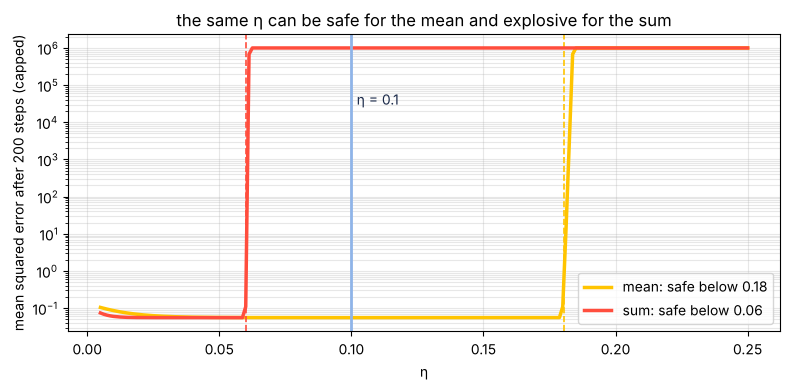

In [11]:
bottom = mse(*LINE_B)


def settles(reduce, eta, steps=6000):
    """True if the walk from line A ends at the bottom of the bowl; False if it runs away."""
    pts, scores = walk(reduce, eta, steps)
    return len(scores) == steps + 1 and scores[-1] - bottom < 1e-9


print("  loss     eta     settles?")
for reduce, eta, expected in [("mean", 0.18, True), ("mean", 0.19, False), ("sum", 0.06, True), ("sum", 0.065, False)]:
    got = settles(reduce, eta)
    print(f"  {reduce:<5}  {eta:<6}  {'settles' if got else 'diverges'}")
    assert got == expected
for reduce, limit in [("mean", limit_mean), ("sum", limit_sum)]:
    for frac in (0.2, 0.5, 0.9, 0.98, 1.02, 1.1, 1.5):               # eta as a fraction of the limit
        assert settles(reduce, frac * limit) == (frac < 1), (reduce, frac)
print("Each loss settles exactly below its own limit, 2/lambda_max.")

etas = np.linspace(0.005, 0.25, 197)
plt.figure(figsize=(8, 4))
for reduce, col, limit in [("mean", GOLD, limit_mean), ("sum", CORAL, limit_sum)]:
    after = [min(walk(reduce, e, 200)[1][-1], 1e6) for e in etas]
    plt.semilogy(etas, after, color=col, lw=2.5, label=f"{reduce}: safe below {limit:.2f}")
    plt.axvline(limit, color=col, ls="--", lw=1.2)
plt.axvline(0.1, color=STEEL, lw=2)
plt.text(0.102, 3e4, "η = 0.1", color=DOT)
plt.xlabel("η"); plt.ylabel("mean squared error after 200 steps (capped)")
plt.title("the same η can be safe for the mean and explosive for the sum"); plt.grid(alpha=0.3, which="both"); plt.legend()
plt.tight_layout()
plt.show()

### Step 10: the rule in one line
**A step size on the sum acts like N times that step size on the mean.** The sum's gradient is N times the mean's, so η × (sum gradient) = (N·η) × (mean gradient): the very same step.

So 0.1 on the sum of three dots acts like 0.3 on the mean, and 0.3 is way past the limit of about 0.18.

In [12]:
for eta in (0.01, 0.05, 0.1):
    pts_s, sc_s = walk("sum", eta, 3)
    pts_m, sc_m = walk("mean", N * eta, 3)
    assert np.allclose(pts_s, pts_m) and np.allclose(sc_s, sc_m)          # identical trajectories
    print(f"eta = {eta} on the sum  =  eta = {fmt(N * eta)} on the mean:  scores " + ", ".join(f"{s:.4g}" for s in sc_s[1:]))
assert np.isclose(N * 0.1, 0.3) and N * 0.1 > limit_mean
assert np.allclose(walk("mean", 0.3, 3)[1][1:], scores_sum[1:])
print(f"0.1 on the sum acts like 0.3 on the mean, past the limit of {limit_mean:.2f}. That is the whole explosion.")

eta = 0.01 on the sum  =  eta = 0.03 on the mean:  scores 0.222, 0.1718, 0.1489
eta = 0.05 on the sum  =  eta = 0.15 on the mean:  scores 0.2167, 0.1625, 0.1361
eta = 0.1 on the sum  =  eta = 0.3 on the mean:  scores 1.2, 5.947, 31.71
0.1 on the sum acts like 0.3 on the mean, past the limit of 0.18. That is the whole explosion.


### Step 11: where you will meet this
A teacher who reacts to the class **average** makes a small correction after a rough day. If she reacts to the **total** of all thirty students' missed points, the same day looks thirty times worse. The total is not wrong; she would just have to react thirty times more gently, and change that again whenever the class size changes. That is why the mean is the usual default: the same step size keeps working when the amount of data changes.

PyTorch's cross-entropy loss (Episode 8's loss) averages by default: `torch.nn.CrossEntropyLoss(reduction='mean')`. Not every piece of code does.

**The common mistake:** copying a learning rate from someone else's setup without checking whether their loss is a mean or a sum.

In [13]:
students = 30
missed = np.full(students, 2.0)                        # a rough day: every student misses 2 points
print(f"class average: {missed.mean():g} missed points;  class total: {missed.sum():g}  ({missed.sum() / missed.mean():g} times bigger)")
assert missed.sum() == students * missed.mean()

# the same eta, more data: copy the three dots 10 times over (30 dots)
u10, y10 = np.tile(u, 10), np.tile(y, 10)
X10 = np.column_stack([u10, np.ones(len(u10))])
lim_mean10 = 2 / np.linalg.eigvalsh(2 / len(u10) * X10.T @ X10)[-1]
lim_sum10 = 2 / np.linalg.eigvalsh(2 * X10.T @ X10)[-1]
print(f"3 dots:  safe limit {limit_mean:.4f} (mean), {limit_sum:.4f} (sum)")
print(f"30 dots: safe limit {lim_mean10:.4f} (mean), {lim_sum10:.4f} (sum)")
assert np.isclose(lim_mean10, limit_mean)              # the mean's limit does not care how much data there is
assert np.isclose(lim_sum10, limit_sum / 10)           # the sum's limit shrinks with every dot you add
print("With the mean, the same step size keeps working when the amount of data changes.")

class average: 2 missed points;  class total: 60  (30 times bigger)
3 dots:  safe limit 0.1803 (mean), 0.0601 (sum)
30 dots: safe limit 0.1803 (mean), 0.0060 (sum)
With the mean, the same step size keeps working when the amount of data changes.


## Part 4 · Check 1
Episode 9's valley was f(z) = 3z², and η = 0.1 settled nicely there. Now the loss is the **sum of four copies** of that valley. (1) What is the new valley? (2) What is the new safe limit? (3) What happens at η = 0.1?

**Predict first**, then run the cell.

In [14]:
kappa_one, copies = 3, 4
kappa_sum = copies * kappa_one
limit_one, limit_four = F(1, kappa_one), F(1, kappa_sum)
eta = F(1, 10)
factor_one = 1 - 2 * eta * kappa_one
factor_four = 1 - 2 * eta * kappa_sum
print(f"one copy:  3z^2, limit 1/3, factor at 0.1 = 1 - 2 x 0.1 x 3 = {float(factor_one)}  (settles)")
print(f"(1) four copies of 3z^2 add up to {kappa_sum}z^2, so kappa = {kappa_sum}")
print(f"(2) safe limit = 1/{kappa_sum} = {float(limit_four):.3f}")
print(f"(3) at 0.1: 2 x 0.1 x 12 = {float(2 * eta * kappa_sum)};  1 - 2.4 = {float(factor_four)}  (bigger than 1 in size: blows up)")
assert kappa_sum == 12 and limit_four == F(1, 12) and round(float(limit_four), 3) == 0.083
assert factor_one == F(2, 5) and 2 * eta * kappa_sum == F(12, 5) and factor_four == F(-7, 5)
assert limit_four < eta < limit_one                    # 0.1 is inside one limit and outside the other
z = F(1)
zs = [z]
for _ in range(3):
    zs.append(zs[-1] - eta * 2 * kappa_sum * zs[-1])   # the rule itself, on 12 z^2
print("z: " + ", ".join(fmt(v) for v in zs) + "   (each step lands on the other side, 1.4 times farther out)")
assert zs == [F(-7, 5) ** k for k in range(4)]
assert all(abs(b) == F(7, 5) * abs(a) and (a > 0) != (b > 0) for a, b in zip(zs, zs[1:]))

one copy:  3z^2, limit 1/3, factor at 0.1 = 1 - 2 x 0.1 x 3 = 0.4  (settles)
(1) four copies of 3z^2 add up to 12z^2, so kappa = 12
(2) safe limit = 1/12 = 0.083
(3) at 0.1: 2 x 0.1 x 12 = 2.4;  1 - 2.4 = -1.4  (bigger than 1 in size: blows up)
z: 1, -1.4, 1.96, -2.744   (each step lands on the other side, 1.4 times farther out)


## Part 5 · Mini-batches: the spoonful

### Step 12: why not use every term?
For a language model, N is not three. It is billions. One honest step would need a slope for every single term. Ruder's survey: batch gradient descent "can be very slow and is intractable for datasets that do not fit in memory".

So do what the chef does with a chunky stew. Stir the pot (shuffle the data), take a spoonful (a small random handful, a **mini-batch**), average just those slopes, and take a step. All N terms together are the **full batch**. **Stochastic** just means random. Ruder: mini-batch gradient descent "is typically the algorithm of choice".

### Step 13: is a handful pointing the right way?
Back to line A, and just the W slopes: 0, 0, 6. The full gradient is their average, 2. The smallest mini-batch is one dot, picked at random: you get 0, or 0, or 6. Never 2.

**Predict first.** If you did this many, many times and averaged all your draws, what number would you land on?

first 20 draws: 6 6 0 0 6 6 0 0 6 0 0 0 0 6 0 6 0 0 0 6
average of the first 60 draws:   2.600
average of all 60,000 draws:     1.997
the 6 came up 33.3% of the time (one dot in three), so the long-run average is (0 + 0 + 6)/3 = 2


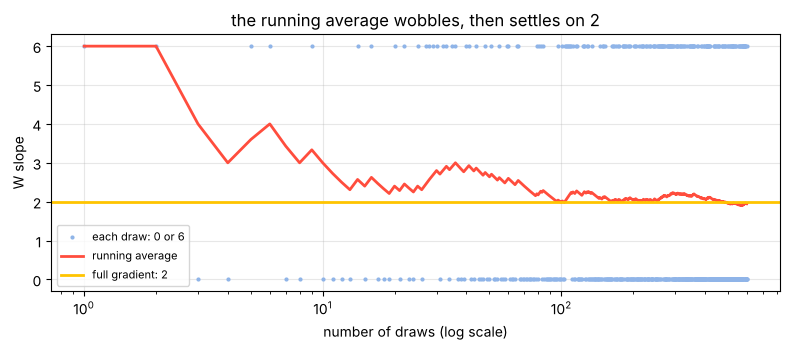

In [15]:
slopes = np.array([0, 0, 6])                           # the W slopes of the three dots on line A
assert np.allclose(slopes, dot_gradients(*LINE_A)[:, 0])
full_gradient = slopes.mean()
assert full_gradient == 2

rng = np.random.default_rng(10)
draws = slopes[rng.integers(0, 3, size=60_000)]        # 60,000 mini-batches of one
first = draws[:60]
print("first 20 draws:", " ".join(str(d) for d in first[:20]))
print(f"average of the first 60 draws:   {first.mean():.3f}")
print(f"average of all 60,000 draws:     {draws.mean():.3f}")
assert set(np.unique(draws)) == {0, 6}                 # a single draw is never 2
assert abs(first.mean() - 2) < 1                       # 60 draws: close
assert abs(draws.mean() - 2) < 0.05                    # 60,000 draws: very close
share_six = (draws == 6).mean()
assert abs(share_six - 1 / 3) < 0.01                   # each dot is picked a third of the time
print(f"the 6 came up {share_six:.1%} of the time (one dot in three), so the long-run average is (0 + 0 + 6)/3 = 2")

running = np.cumsum(draws[:600]) / np.arange(1, 601)
plt.figure(figsize=(8, 3.6))
plt.plot(np.arange(1, 601), draws[:600], ".", color=STEEL, ms=4, label="each draw: 0 or 6")
plt.plot(np.arange(1, 601), running, color=CORAL, lw=2, label="running average")
plt.axhline(2, color=GOLD, lw=2, label="full gradient: 2")
plt.xscale("log"); plt.xlabel("number of draws (log scale)"); plt.ylabel("W slope")
plt.title("the running average wobbles, then settles on 2"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

That is not luck. Every dot is equally likely to be picked, so the average over all the picks is the average over all the dots, and that is the full gradient. The word is **unbiased**: usually off on any one draw, but right on average. It needs the picks to be random: if the spoon always dips into the same corner of the pot, the taste is off.

In [16]:
averages, mean1, var1 = batch_stats(slopes, 1)
assert mean1 == 2                                      # exactly the full gradient, no simulation needed
always_dot_3 = slopes[2]                               # a spoon that always dips into the same corner
assert always_dot_3 != full_gradient
print(f"random picks: the average over all picks is exactly {mean1}.  Always picking dot 3 gives {always_dot_3}: biased.")

random picks: the average over all picks is exactly 2.  Always picking dot 3 gives 6: biased.


### Step 14: the cost is noise. Measure it.
**Variance** = the average squared distance from the mean. Squared, so misses above and below cannot cancel.

In [17]:
distances = [int(s) - 2 for s in slopes]
squares = [d ** 2 for d in distances]
print(f"distances from 2: {distances};  squared: {squares};  total {sum(squares)};  divided by 3: {F(sum(squares), 3)}")
assert squares == [4, 4, 16] and sum(squares) == 24 and F(sum(squares), 3) == 8
assert var1 == 8 and np.isclose(np.var(slopes), 8)
print(f"variance of a mini-batch of one: {var1}")

distances from 2: [-2, -2, 4];  squared: [4, 4, 16];  total 24;  divided by 3: 8
variance of a mini-batch of one: 8


### Step 15: two dots per mini-batch
One rule: after the first pick, **put the dot back**, so the same dot can come up twice. Three choices, then three choices again: 9 equally likely pairs. Average each pair.

**Predict first.** What averages can a pair give, and how many pairs give each one?

In [18]:
averages2, mean2, var2 = batch_stats(slopes, 2)
counts = {int(a): averages2.count(a) for a in sorted(set(averages2))}
print(f"{len(averages2)} pairs.  average -> number of pairs: {counts}")
assert len(averages2) == 9 and counts == {0: 4, 3: 4, 6: 1}
total = sum(n * (a - 2) ** 2 for a, n in counts.items())
print(f"mean of the 9 averages: {mean2}")
print(f"variance: (4 x 4 + 4 x 1 + 1 x 16)/9 = {total}/9 = {var2}")
assert mean2 == 2 and total == 36 and var2 == 4
assert var2 == var1 / 2
print("Twice the dots, half the variance.")

9 pairs.  average -> number of pairs: {0: 4, 3: 4, 6: 1}
mean of the 9 averages: 2
variance: (4 x 4 + 4 x 1 + 1 x 16)/9 = 36/9 = 4
Twice the dots, half the variance.


### Step 16: eight per batch, and the typical miss
With eight picks there are 3⁸ = 6,561 equally likely mini-batches. The cell lists all of them. Variance is in squared units, so for the **typical miss** take the square root.

6,561 mini-batches of eight:  mean 2,  variance 1
batch of 1: variance 8,  typical miss = sqrt(8) = 2.83
batch of 2: variance 4,  typical miss = sqrt(4) = 2.00
batch of 8: variance 1,  typical miss = sqrt(1) = 1.00
Eight times the data, and the miss didn't even drop to a third.


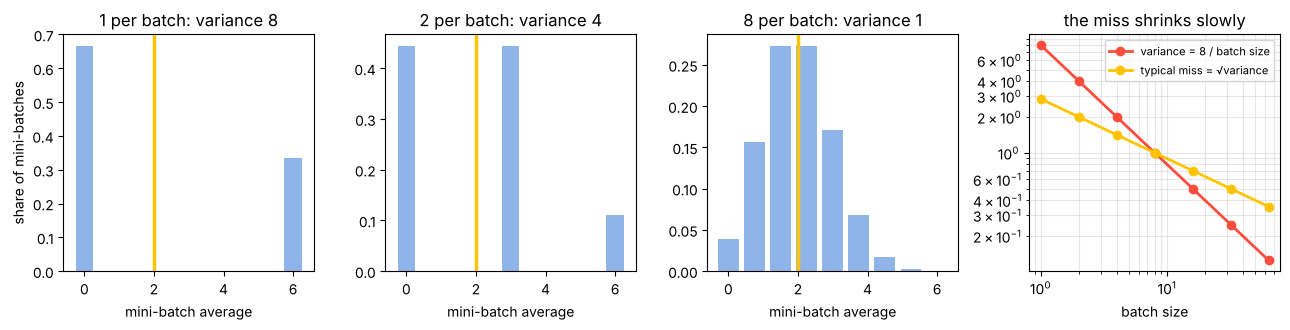

In [19]:
averages8, mean8, var8 = batch_stats(slopes, 8)
print(f"{len(averages8):,} mini-batches of eight:  mean {mean8},  variance {var8}")
assert len(averages8) == 6561 and mean8 == 2 and var8 == 1
variances = {1: var1, 2: var2, 8: var8}
for m, v in variances.items():
    assert v == F(8, m)                                # the variance falls like 1 / batch size
    print(f"batch of {m}: variance {v},  typical miss = sqrt({v}) = {float(v) ** 0.5:.2f}")
misses = {m: float(v) ** 0.5 for m, v in variances.items()}
assert [round(misses[m], 2) for m in (1, 2, 8)] == [2.83, 2.0, 1.0] and round(misses[1], 1) == 2.8
assert misses[8] > misses[1] / 3                       # eight times the data, and the miss did not even drop to a third
print("Eight times the data, and the miss didn't even drop to a third.")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (m, avgs) in zip(axes, [(1, averages), (2, averages2), (8, averages8)]):
    vals = sorted(set(avgs))
    ax.bar([float(v) for v in vals], [avgs.count(v) / len(avgs) for v in vals], width=0.5 if m < 8 else 0.6, color=STEEL)
    ax.axvline(2, color=GOLD, lw=2.5)
    ax.set_xlim(-0.6, 6.6); ax.set_xlabel("mini-batch average"); ax.set_title(f"{m} per batch: variance {variances[m]}")
axes[0].set_ylabel("share of mini-batches")
ax = axes[3]
ms = np.array([1, 2, 4, 8, 16, 32, 64])
ax.loglog(ms, 8 / ms, "-o", color=CORAL, lw=2, label="variance = 8 / batch size")
ax.loglog(ms, np.sqrt(8 / ms), "-o", color=GOLD, lw=2, label="typical miss = √variance")
ax.set_xlabel("batch size"); ax.set_title("the miss shrinks slowly"); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

### Step 17: a note on "put the dot back"
The video draws **with replacement** (the dot goes back), because the arithmetic is cleanest: the variance is exactly (variance of one draw) / (batch size). Real training usually shuffles the data and walks through it, so within one mini-batch no example repeats: sampling **without replacement**.

With only three dots that matters. There are just 3 different pairs, and their averages are 0, 3, 3, so the variance is 2, not 4. In general the with-replacement variance gets multiplied by (N − m)/(N − 1) for a batch of m out of N. For three dots and pairs that is 1/2. For a real dataset, with N in the billions and m in the hundreds, the factor is 1 to many decimal places, and the two answers agree.

In [20]:
def pairs_without_replacement(values):
    """Every pair of two DIFFERENT examples: the averages, their mean and their variance (exact)."""
    values = [F(v) for v in values]
    avgs = [(values[i] + values[j]) / 2 for i in range(len(values)) for j in range(i + 1, len(values))]
    mean = sum(avgs) / len(avgs)
    return avgs, mean, sum((a - mean) ** 2 for a in avgs) / len(avgs)


avgs_wo, mean_wo, var_wo = pairs_without_replacement(slopes)
print(f"3 dots, pairs without replacement: averages {[int(a) for a in avgs_wo]}, mean {mean_wo}, variance {var_wo}  (with replacement: {var2})")
assert sorted(avgs_wo) == [0, 3, 3] and mean_wo == 2 and var_wo == 2          # still unbiased; less noisy
assert var_wo == var2 * F(3 - 2, 3 - 1)

print("\ncopies of the pot (slopes 0, 0, 6 repeated), pairs:")
print("       N   with   without   ratio = (N - 2)/(N - 1)")
for copies_ in (1, 2, 5, 20, 100):
    pot = list(slopes) * copies_
    n = len(pot)
    _, m_, v_ = pairs_without_replacement(pot)
    assert m_ == 2 and v_ == 4 * F(n - 2, n - 1)       # the correction factor, exactly
    print(f"  {n:>6}   {4:>4}   {float(v_):>7.4f}   {float(v_ / 4):.4f}")
billions = 3_000_000_000
factor = F(billions - 256, billions - 1)               # a batch of 256 out of three billion
print(f"N = {billions:,}, batch of 256: factor {float(factor):.10f}")
assert 1 - factor < 1e-7
print("For large N the difference vanishes, so the simple 1/(batch size) rule is the one to remember.")

3 dots, pairs without replacement: averages [0, 3, 3], mean 2, variance 2  (with replacement: 4)

copies of the pot (slopes 0, 0, 6 repeated), pairs:
       N   with   without   ratio = (N - 2)/(N - 1)
       3      4    2.0000   0.5000
       6      4    3.2000   0.8000
      15      4    3.7143   0.9286
      60      4    3.9322   0.9831


     300      4    3.9866   0.9967
N = 3,000,000,000, batch of 256: factor 0.9999999150
For large N the difference vanishes, so the simple 1/(batch size) rule is the one to remember.


### Step 18: a hundred times the work, ten times the precision
Goodfellow, Bengio and Courville (§8.1.3) compare a gradient estimated from 100 examples with one from 10,000: the second needs 100 times more computation, but reduces the standard error (the typical miss) only by a factor of 10. Here it is on our slopes.

In [21]:
se_100, se_10000 = (8 / 100) ** 0.5, (8 / 10_000) ** 0.5
print(f"typical miss with 100 examples: {se_100:.4f};  with 10,000: {se_10000:.4f};  ratio {se_100 / se_10000:.0f}")
assert np.isclose(se_100 / se_10000, 10) and 10_000 / 100 == 100

rng = np.random.default_rng(10)                        # ... and measured, on 2,000 simulated mini-batches of each size
sim_100 = slopes[rng.integers(0, 3, size=(2000, 100))].mean(axis=1)
sim_10000 = slopes[rng.integers(0, 3, size=(2000, 10_000))].mean(axis=1)
print(f"measured: {sim_100.std():.4f} and {sim_10000.std():.4f};  ratio {sim_100.std() / sim_10000.std():.1f}")
assert abs(sim_100.mean() - 2) < 0.05 and abs(sim_10000.mean() - 2) < 0.005
assert 9 < sim_100.std() / sim_10000.std() < 11
print("100 times the examples, a step only 10 times more precise. Better to spend that work on 100 quick steps.")

typical miss with 100 examples: 0.2828;  with 10,000: 0.0283;  ratio 10


measured: 0.2871 and 0.0273;  ratio 10.5
100 times the examples, a step only 10 times more precise. Better to spend that work on 100 quick steps.


## Part 6 · Line B: still moving at the bottom

### Step 19: slopes that add up to zero
Line B (W = 1.5, β = 2/3) is the best line: the full gradient is exactly zero. Nothing should move. But look at the dots one at a time.

In [22]:
WB, bB = F(3, 2), F(2, 3)
eB = errors_exact(WB, bB)
gB = dot_gradients_exact(WB, bB)
w_slopes, b_slopes = [g[0] for g in gB], [g[1] for g in gB]
print(f"errors on line B: {', '.join(str(e) for e in eB)}")
print(f"per-dot W slopes:    {', '.join(str(s) for s in w_slopes)}    sum {sum(w_slopes)}")
print(f"per-dot beta slopes: {', '.join(str(s) for s in b_slopes)}   sum {sum(b_slopes)}")
assert w_slopes == [F(1, 3), F(-4, 3), 1] and sum(w_slopes) == 0
assert b_slopes == [F(1, 3), F(-2, 3), F(1, 3)] and sum(b_slopes) == 0
assert all(s != 0 for s in w_slopes)                   # yet none of them is zero on its own
assert np.allclose(dot_gradients(*LINE_B).mean(axis=0), 0)
print("The full gradient is zero. Yet no single dot's slope is: a mini-batch step still moves, even at the very bottom.")

errors on line B: -1/6, 1/3, -1/6
per-dot W slopes:    1/3, -4/3, 1    sum 0
per-dot beta slopes: 1/3, -2/3, 1/3   sum 0
The full gradient is zero. Yet no single dot's slope is: a mini-batch step still moves, even at the very bottom.


### Step 20: fixed η against a shrinking η
A step is η × slope. If the slope from a handful never quite reaches zero, the only way to quiet the jiggling is to shrink η. Goodfellow et al. (§8.3.1): the noise "does not vanish even when we arrive at a minimum", which is why the learning rate is lowered over time.

Start exactly on line B and take 3,000 steps with mini-batches of one: once with a fixed η = 0.05, once with η shrinking as 0.05 / (1 + step/100). Both runs see the same picks.

full batch:  stays on line B exactly
fixed eta:   typical distance from line B  0.085 (steps 500 to 1000)  0.077 (last 500)
shrinking:   typical distance from line B  0.027 (steps 500 to 1000)  0.014 (last 500)
With a fixed eta the jiggle never dies down. Shrink eta, and it does.


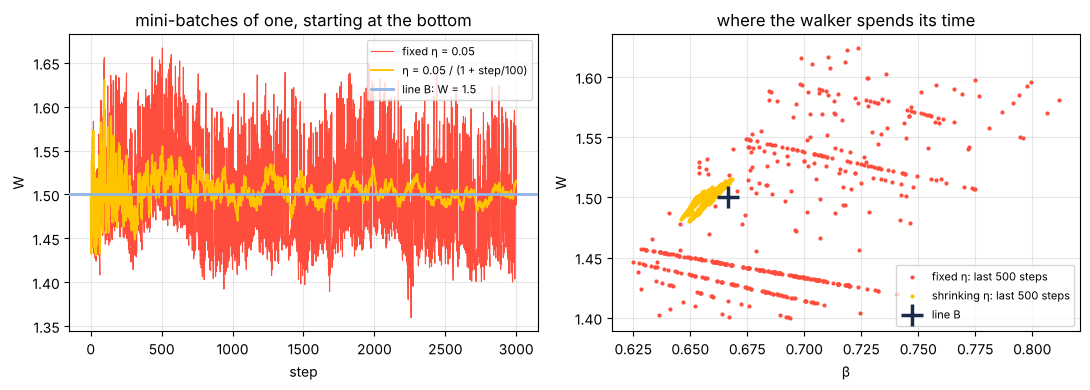

In [23]:
def sgd(schedule, steps=3000, seed=10, start=LINE_B):
    """Mini-batch-of-one gradient descent. schedule(k) gives eta at step k. Returns the (W, beta) points."""
    rng = np.random.default_rng(seed)
    p = np.array(start, dtype=float)
    pts = [p]
    for k in range(steps):
        i = rng.integers(0, N)                         # pick one dot at random
        p = p - schedule(k) * dot_gradients(*p)[i]
        pts.append(p)
    return np.array(pts)


fixed = sgd(lambda k: 0.05)
decay = sgd(lambda k: 0.05 / (1 + k / 100))
full = walk("mean", 0.05, 50, start=LINE_B)[0]         # the full batch, for comparison
jiggle = lambda pts: float(np.sqrt(((pts - np.array(LINE_B)) ** 2).sum(axis=1).mean()))   # typical distance from line B

assert np.allclose(full, LINE_B)                       # the full batch does not move at all
assert not np.allclose(fixed[1], LINE_B)               # the very first mini-batch step leaves the bottom
early_f, late_f = jiggle(fixed[500:1000]), jiggle(fixed[-500:])
early_d, late_d = jiggle(decay[500:1000]), jiggle(decay[-500:])
print(f"full batch:  stays on line B exactly")
print(f"fixed eta:   typical distance from line B  {early_f:.3f} (steps 500 to 1000)  {late_f:.3f} (last 500)")
print(f"shrinking:   typical distance from line B  {early_d:.3f} (steps 500 to 1000)  {late_d:.3f} (last 500)")
assert 0.5 < late_f / early_f < 2                      # fixed eta: the jiggle never dies down
assert late_d < early_d and late_d < late_f / 3        # shrinking eta: the jiggle shrinks
print("With a fixed eta the jiggle never dies down. Shrink eta, and it does.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(fixed[:, 0], color=CORAL, lw=0.8, label="fixed η = 0.05")
ax.plot(decay[:, 0], color=GOLD, lw=1.4, label="η = 0.05 / (1 + step/100)")
ax.axhline(LINE_B[0], color=STEEL, lw=2, zorder=5, label="line B: W = 1.5")
ax.set_xlabel("step"); ax.set_ylabel("W"); ax.set_title("mini-batches of one, starting at the bottom"); ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
ax = axes[1]
ax.plot(fixed[-500:, 1], fixed[-500:, 0], ".", color=CORAL, ms=4, label="fixed η: last 500 steps")
ax.plot(decay[-500:, 1], decay[-500:, 0], ".", color=GOLD, ms=4, label="shrinking η: last 500 steps")
ax.plot([LINE_B[1]], [LINE_B[0]], "+", color=DOT, ms=16, mew=2.5, label="line B")
ax.set_xlabel("β"); ax.set_ylabel("W"); ax.set_title("where the walker spends its time"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Part 7 · Check 2
Three examples have slopes 0, 3 and 9. (1) What is the full gradient, their average? (2) What is the variance of a mini-batch of one? (3) With two per batch, is the step twice as accurate?

**Predict first**, then run the cell.

In [24]:
check = [0, 3, 9]
avg = F(sum(check), 3)
dist = [abs(s - avg) for s in check]
sq = [d ** 2 for d in dist]
var_one = F(sum(sq), 3)
var_two = var_one / 2
miss_one, miss_two = float(var_one) ** 0.5, float(var_two) ** 0.5
print(f"(1) (0 + 3 + 9)/3 = {sum(check)}/3 = {avg}")
print(f"(2) distances from {avg}: {', '.join(str(d) for d in dist)};  squared: {', '.join(str(s) for s in sq)};  total {sum(sq)};  divided by 3: {var_one}")
print(f"(3) two per batch halves the variance, to {var_two}.  Typical miss: sqrt(14) = {miss_one:.2f}  ->  sqrt(7) = {miss_two:.2f}")
print(f"    the miss only shrinks by a factor of {miss_one / miss_two:.2f}, not 2: not twice as accurate")
assert sum(check) == 12 and avg == 4 and dist == [4, 1, 5] and sq == [16, 1, 25] and sum(sq) == 42
assert var_one == 14 and var_two == 7
assert round(miss_one, 2) == 3.74 and round(miss_two, 2) == 2.65 and round(miss_one, 1) == 3.7 and int(miss_two * 10) == 26
assert np.isclose(miss_one / miss_two, 2 ** 0.5) and miss_two > miss_one / 2
_, m1, v1 = batch_stats(check, 1)                      # ... and by listing every mini-batch
_, m2, v2 = batch_stats(check, 2)
assert (m1, v1) == (4, 14) and (m2, v2) == (4, 7)

(1) (0 + 3 + 9)/3 = 12/3 = 4
(2) distances from 4: 4, 1, 5;  squared: 16, 1, 25;  total 42;  divided by 3: 14
(3) two per batch halves the variance, to 7.  Typical miss: sqrt(14) = 3.74  ->  sqrt(7) = 2.65
    the miss only shrinks by a factor of 1.41, not 2: not twice as accurate


## Part 8 · Try it yourself
Change the values in the next cells and re-run them. The self-checks tell you whether your prediction, or your own hand calculation, matches.

1. Run line A with the mean and with the sum, and watch one settle and the other explode.
2. Draw mini-batches of one, two and eight, and check that the average stays at 2 while the spread shrinks.
3. Make up three slopes of your own, and work out the variance by hand.

The one mistake to avoid: reusing a learning rate without checking whether the loss is a mean or a sum.

In [25]:
my_eta = 0.1                           # 1. any step size > 0 (try 0.05, 0.17, 0.2)
my_steps = 3
my_guess_mean = None                   #    your prediction for the mean: "settles" or "explodes"
my_guess_sum = None                    #    your prediction for the sum:  "settles" or "explodes"

for reduce, limit, guess in [("mean", limit_mean, my_guess_mean), ("sum", limit_sum, my_guess_sum)]:
    _, sc = walk(reduce, my_eta, my_steps)
    truth = "settles" if my_eta < limit else "explodes"
    print(f"{reduce:<4} (safe below {limit:.4f}): scores " + ", ".join(f"{s:.4g}" for s in sc) + f"   -> {truth}")
    if guess is not None:
        print("     your prediction matches" if guess == truth else f"     not this time: compare {my_eta} with the limit {limit:.4f}")
    assert settles(reduce, my_eta) == (truth == "settles") or abs(my_eta / limit - 1) < 0.02   # (too close to the limit to call)
assert my_eta > 0
assert np.allclose(walk("sum", my_eta, my_steps)[1], walk("mean", N * my_eta, my_steps)[1])   # eta on the sum = N x eta on the mean
if my_eta == 0.1 and my_steps == 3:
    assert [round(s, 2) for s in walk("sum", 0.1, 3)[1][1:]] == [1.2, 5.95, 31.71]

mean (safe below 0.1803): scores 0.3333, 0.1333, 0.1274, 0.124   -> settles
sum  (safe below 0.0601): scores 0.3333, 1.2, 5.947, 31.71   -> explodes


In [26]:
my_sizes = (1, 2, 8)                   # 2. mini-batch sizes to try
my_draws = 20_000                      #    how many mini-batches of each size
my_seed = 0                            #    change the seed for a different run

rng = np.random.default_rng(my_seed)
print("batch size   average of the draws   variance (measured)   variance (exact: 8 / size)   typical miss")
for m in my_sizes:
    batch_averages = slopes[rng.integers(0, 3, size=(my_draws, m))].mean(axis=1)
    exact = 8 / m
    print(f"{m:>10}   {batch_averages.mean():>20.3f}   {batch_averages.var():>19.3f}   {exact:>26.3f}   {exact ** 0.5:>12.2f}")
    if my_draws >= 5000:                               # enough draws for the checks to be fair
        assert abs(batch_averages.mean() - 2) < 5 * (exact / my_draws) ** 0.5 + 1e-9      # the average stays at 2
        assert abs(batch_averages.var() - exact) < 0.15 * exact                            # the spread shrinks like 1 / size
print("The average stays at 2. The variance falls like 1 / batch size; the typical miss only like 1 / sqrt(batch size).")

batch size   average of the draws   variance (measured)   variance (exact: 8 / size)   typical miss
         1                  1.998                 7.996                        8.000           2.83
         2                  1.985                 3.997                        4.000           2.00
         8                  2.002                 0.985                        1.000           1.00
The average stays at 2. The variance falls like 1 / batch size; the typical miss only like 1 / sqrt(batch size).


In [27]:
my_slopes = [1, 2, 6]                  # 3. three slopes of your own (whole numbers keep the pencil work easy)
my_average = None                      #    your pencil answer: the full gradient (their average)
my_variance = None                     #    your pencil answer: the variance of a mini-batch of one

_, exact_mean, exact_var = batch_stats(my_slopes, 1)
if my_average is None or my_variance is None:
    print("Enter your answers in my_average and my_variance. Hint: average the slopes; then average the squared distances from it.")
else:
    ok_mean = np.isclose(float(my_average), float(exact_mean))
    ok_var = np.isclose(float(my_variance), float(exact_var))
    print(f"average:  {'matches' if ok_mean else 'not quite'}  (the cell gets {exact_mean})")
    print(f"variance: {'matches' if ok_var else 'not quite'}  (the cell gets {exact_var})")
_, pair_mean, pair_var = batch_stats(my_slopes, 2)
print(f"two per batch (put back): mean {pair_mean}, variance {pair_var};  typical miss {float(exact_var) ** 0.5:.2f} -> {float(pair_var) ** 0.5:.2f}")
assert len(my_slopes) >= 2
assert pair_mean == exact_mean and pair_var == exact_var / 2          # unbiased, and half the variance, for any slopes
assert exact_var == sum((F(s) - exact_mean) ** 2 for s in my_slopes) / len(my_slopes)

Enter your answers in my_average and my_variance. Hint: average the slopes; then average the squared distances from it.
two per batch (put back): mean 3, variance 7/3;  typical miss 2.16 -> 1.53


In [28]:
print("All Episode 10 checks passed.")

All Episode 10 checks passed.
